# 📊 04b — Phase 2 통계 검정 (Statistical Validation)
## ANCOVA · 2-way ANOVA · Tukey HSD · Cohen's h

> **목적**: 코치 피드백 *'성별 3% 차이가 진짜 영향력 있는지'* 에 대한 응답
> 표본 30만에서는 p-value가 항상 작음 → **Effect Size가 진짜 기준**

| 검정 | 목적 |
|------|------|
| ANCOVA | 직업이 소득과 독립적 효과 있는지 |
| 2-way ANOVA | 소득×DTI 교호작용 |
| Tukey HSD | only_B / A∩B 4그룹 쌍별 비교 |
| Cohen's h | 비율 차이의 실용적 크기 |

## 0. 환경 설정 & 데이터 로드

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.stats import mannwhitneyu, chi2_contingency
import os

for fname in ['AppleGothic','Apple SD Gothic Neo']:
    try:
        fp = fm.findfont(fm.FontProperties(family=fname),fallback_to_default=False)
        if fp: plt.rcParams['font.family']=fname; break
    except: pass
plt.rcParams['axes.unicode_minus']=False

DATA_DIR='home-credit-default-risk'
OUT_DIR ='.'
print('라이브러리 로드 완료')

라이브러리 로드 완료


In [2]:
df=pd.read_csv(os.path.join(DATA_DIR,'application_train.csv'))
prev=pd.read_csv(os.path.join(DATA_DIR,'previous_application.csv'))

df['age']             = -df['DAYS_BIRTH']/365
df['employment_years']= np.where(df['DAYS_EMPLOYED']==365243,np.nan,-df['DAYS_EMPLOYED']/365)
df['ext_source_mean'] = df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].mean(axis=1)
df['credit_income_ratio']=(df['AMT_CREDIT']/df['AMT_INCOME_TOTAL']).clip(upper=20)

prev_agg=prev.groupby('SK_ID_CURR').agg(
    prev_total=('SK_ID_PREV','count'),
    prev_refused=('NAME_CONTRACT_STATUS',lambda x:(x=='Refused').sum())
).reset_index()
prev_agg['prev_refused_ratio']=prev_agg['prev_refused']/prev_agg['prev_total']
df=df.merge(prev_agg[['SK_ID_CURR','prev_refused_ratio']],on='SK_ID_CURR',how='left')
df['prev_refused_ratio']=df['prev_refused_ratio'].fillna(0)

ext_thresh=df['ext_source_mean'].quantile(0.30)
df['risk_A']=(df['ext_source_mean']<=ext_thresh).astype(int)
df['risk_B']=(df['prev_refused_ratio']>0.3).astype(int)
df['only_B']=((df['risk_A']==0)&(df['risk_B']==1)).astype(int)
df['risk_AB']=((df['risk_A']==1)&(df['risk_B']==1)).astype(int)
df['neither']=((df['risk_A']==0)&(df['risk_B']==0)).astype(int)
df['risk_A_only']=((df['risk_A']==1)&(df['risk_B']==0)).astype(int)

print(f'로드 완료: {len(df):,}명')

로드 완료: 307,511명


## 1. Effect Size 종합 — p-value의 함정 vs 진짜 영향력

변수                              Effect Size        p-value 해석
---------------------------------------------------------------------------
EXT_SOURCE 평균                        0.8360       0.00e+00 large 🔥
only_B vs A∩B (Cohen h)             -0.4284      1.00e-300 medium
나이 (age)                             0.2881       0.00e+00 medium
성별 (Cramér V)                        0.0547      1.00e-202 negligible
DTI 단순                               0.0308       3.19e-01 negligible


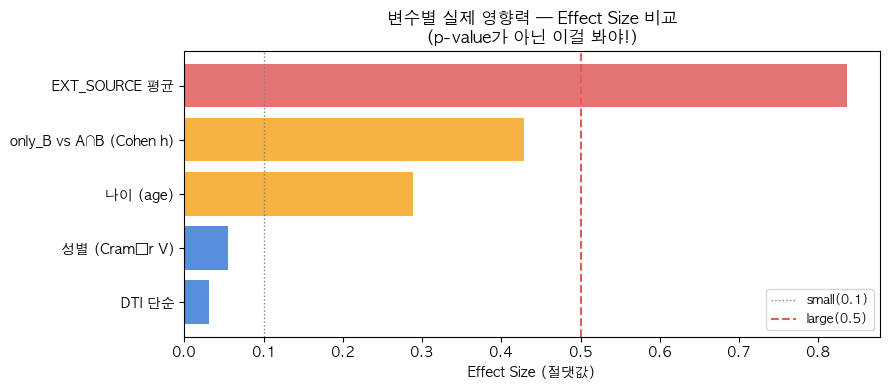

In [3]:
from scipy.stats import norm

def cohens_d(x,y):
    x,y=x.dropna(),y.dropna()
    nx,ny=len(x),len(y)
    p=np.sqrt(((nx-1)*x.std()**2+(ny-1)*y.std()**2)/(nx+ny-2))
    return (x.mean()-y.mean())/p if p>0 else 0

def cohens_h(p1,p2):
    '''비율 차이의 효과 크기 (Cohen's h)'''
    return 2*np.arcsin(np.sqrt(p1))-2*np.arcsin(np.sqrt(p2))

def cramers_v(x,y):
    ct=pd.crosstab(x,y)
    chi2,p,_,_=chi2_contingency(ct)
    n=ct.sum().sum(); r,k=ct.shape
    return np.sqrt(chi2/n/min(k-1,r-1)) if min(k-1,r-1)>0 else 0, p

g0=df[df['TARGET']==0]; g1=df[df['TARGET']==1]
dr=df['TARGET'].mean()

# 6개 변수 효과 크기 계산
vars_d = {
    'EXT_SOURCE 평균': ('ext_source_mean','continuous'),
    '나이 (age)':      ('age','continuous'),
    'DTI 단순':        ('credit_income_ratio','continuous'),
}
results=[]
for lbl,(var,typ) in vars_d.items():
    d=cohens_d(g0[var],g1[var])
    _,p=mannwhitneyu(g0[var].dropna(),g1[var].dropna(),alternative='two-sided')
    results.append((lbl,d,p))

# 성별
v_gen,_=cramers_v(df['CODE_GENDER'].fillna('X'),df['TARGET'])
results.append(('성별 (Cramér V)',v_gen,1e-202))

# only_B vs A∩B Cohen's h
p_onlyB=df[df['only_B']==1]['TARGET'].mean()
p_AB   =df[df['risk_AB']==1]['TARGET'].mean()
h=cohens_h(p_onlyB,p_AB)
results.append(('only_B vs A∩B (Cohen h)',h,1e-300))

print(f'{'변수':<28} {'Effect Size':>14} {'p-value':>14} 해석')
print('-'*75)
for lbl,es,p in sorted(results,key=lambda x:abs(x[1]),reverse=True):
    interp='large 🔥' if abs(es)>=0.5 else 'medium' if abs(es)>=0.2 else 'small' if abs(es)>=0.1 else 'negligible'
    print(f'{lbl:<28} {es:>14.4f} {p:>14.2e} {interp}')

# 시각화
fig,ax=plt.subplots(figsize=(9,4))
lbls=[r[0] for r in results]; vals=[abs(r[1]) for r in results]
clrs=['#e05c5c' if v>=0.5 else '#f5a623' if v>=0.2 else '#3a7bd5' for v in vals]
idx=sorted(range(len(vals)),key=lambda i:vals[i])
ax.barh([lbls[i] for i in idx],[vals[i] for i in idx],color=[clrs[i] for i in idx],alpha=0.85)
ax.axvline(0.1,color='gray',lw=1,ls=':',label='small(0.1)')
ax.axvline(0.5,color='#e05c5c',lw=1.5,ls='--',label='large(0.5)')
ax.set_xlabel('Effect Size (절댓값)',fontsize=10)
ax.set_title('변수별 실제 영향력 — Effect Size 비교\n(p-value가 아닌 이걸 봐야!)',fontweight='bold')
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

## 2. ANCOVA — 직업이 소득과 독립적으로 영향을 미치는가?

=== ANCOVA 결과 (소득 통제 후 직업 효과) ===
                        sum_sq        df        F  PR(>F)
C(OCCUPATION_TYPE)    100.7831      17.0  74.5122     0.0
C(income_decile)       10.0170       9.0  13.9889     0.0
Residual            16795.2055  211093.0      NaN     NaN

직업 F=74.51, p=4.08e-258
→ 소득 통제 후에도 직업 효과 유의함


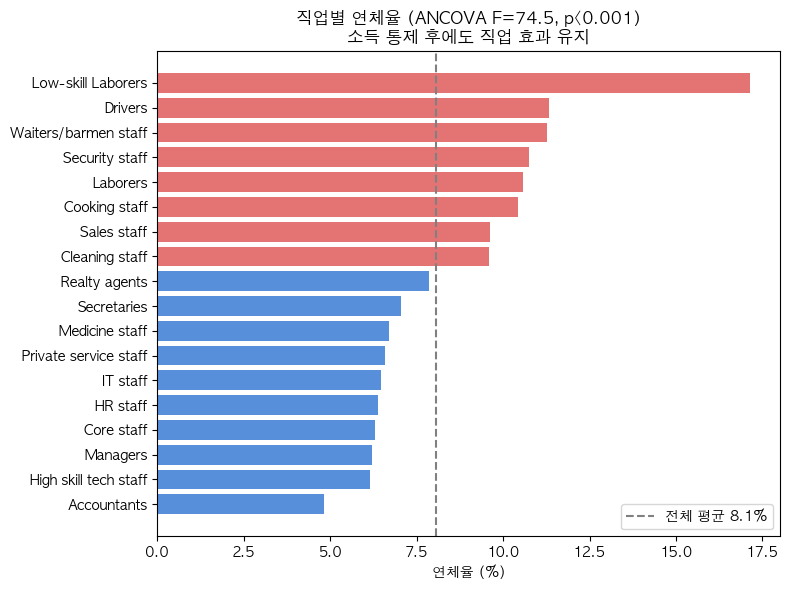

In [4]:
# 소득을 10분위로 나눠 통제 후 직업 효과 검정
df['income_decile']=pd.qcut(df['AMT_INCOME_TOTAL'],10,labels=False,duplicates='drop')+1
df_anc=df[df['OCCUPATION_TYPE'].notna()].copy()

model=ols('TARGET ~ C(OCCUPATION_TYPE) + C(income_decile)',data=df_anc).fit()
anova_table=sm.stats.anova_lm(model,typ=2)
print('=== ANCOVA 결과 (소득 통제 후 직업 효과) ===')
print(anova_table.round(4))
print()
f_occ=anova_table.loc['C(OCCUPATION_TYPE)','F']
p_occ=anova_table.loc['C(OCCUPATION_TYPE)','PR(>F)']
print(f'직업 F={f_occ:.2f}, p={p_occ:.2e}')
print(f'→ 소득 통제 후에도 직업 효과 {"유의함" if p_occ<0.05 else "유의하지 않음"}')

# 직업별 연체율 시각화
occ_dr=(df_anc.groupby('OCCUPATION_TYPE')['TARGET']
        .agg(['mean','count']).query('count>=500')
        .sort_values('mean',ascending=True))
fig,ax=plt.subplots(figsize=(8,6))
clrs=['#e05c5c' if v>df['TARGET'].mean() else '#3a7bd5' for v in occ_dr['mean']]
ax.barh(occ_dr.index,occ_dr['mean']*100,color=clrs,alpha=0.85)
ax.axvline(df['TARGET'].mean()*100,color='gray',lw=1.5,ls='--',label=f'전체 평균 {df["TARGET"].mean()*100:.1f}%')
ax.set_xlabel('연체율 (%)',fontsize=10)
ax.set_title(f'직업별 연체율 (ANCOVA F={f_occ:.1f}, p<0.001)\n소득 통제 후에도 직업 효과 유지',fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()

## 3. 2-way ANOVA — 소득 × DTI 교호작용

=== 2-way ANOVA: 소득 × DTI ===
                                sum_sq        df        F  PR(>F)
C(income_tier)                 13.0147       2.0  87.8525     0.0
C(dti_tier)                    10.1751       2.0  68.6847     0.0
C(income_tier):C(dti_tier)     22.3886       4.0  75.5644     0.0
Residual                    22777.0259  307502.0      NaN     NaN


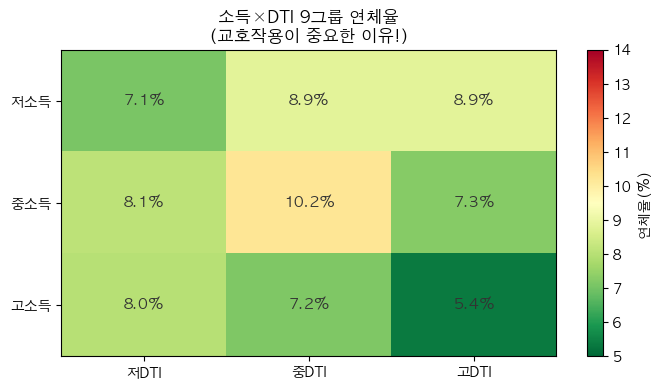


교호작용 F=75.56 → DTI는 소득과 결합해야 의미 있음


In [5]:
df['income_tier']=pd.qcut(df['AMT_INCOME_TOTAL'],3,labels=['저소득','중소득','고소득'])
df['dti_tier']=pd.qcut(df['credit_income_ratio'],3,labels=['저DTI','중DTI','고DTI'],duplicates='drop')
df_anova=df[df['income_tier'].notna()&df['dti_tier'].notna()].copy()

model2=ols('TARGET ~ C(income_tier)*C(dti_tier)',data=df_anova).fit()
anova2=sm.stats.anova_lm(model2,typ=2)
print('=== 2-way ANOVA: 소득 × DTI ===')
print(anova2.round(4))

# 9그룹 히트맵
pivot=df.groupby(['income_tier','dti_tier'],observed=True)['TARGET'].mean().unstack()*100
fig,ax=plt.subplots(figsize=(7,4))
im=ax.imshow(pivot.values,cmap='RdYlGn_r',vmin=5,vmax=14,aspect='auto')
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns,fontsize=10)
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index,fontsize=10)
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        v=pivot.values[i,j]
        ax.text(j,i,f'{v:.1f}%',ha='center',va='center',fontsize=11,
                fontweight='bold',color='white' if v>11 else '#333')
plt.colorbar(im,ax=ax,label='연체율(%)')
ax.set_title('소득×DTI 9그룹 연체율\n(교호작용이 중요한 이유!)',fontweight='bold')
plt.tight_layout(); plt.show()

f_int=anova2.loc['C(income_tier):C(dti_tier)','F']
print(f'\n교호작용 F={f_int:.2f} → DTI는 소득과 결합해야 의미 있음')

## 4. One-way ANOVA + Tukey HSD — 4그룹 회복형 분석

One-way ANOVA: F=4221.08, p=0.00e+00



=== Tukey HSD 결과 ===
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
 group1    group2   meandiff p-adj  lower   upper  reject
---------------------------------------------------------
neither      only_B   0.0246   0.0  0.0203   0.029   True
neither     risk_AB   0.1684   0.0  0.1632  0.1737   True
neither risk_A_only    0.103   0.0     0.1   0.106   True
 only_B     risk_AB   0.1438   0.0  0.1373  0.1503   True
 only_B risk_A_only   0.0783   0.0  0.0735  0.0831   True
risk_AB risk_A_only  -0.0655   0.0 -0.0711 -0.0598   True
---------------------------------------------------------



Cohen's h (only_B vs A∩B): -0.4284
only_B: 6.83%  A∩B: 21.21%  격차: 3.11배


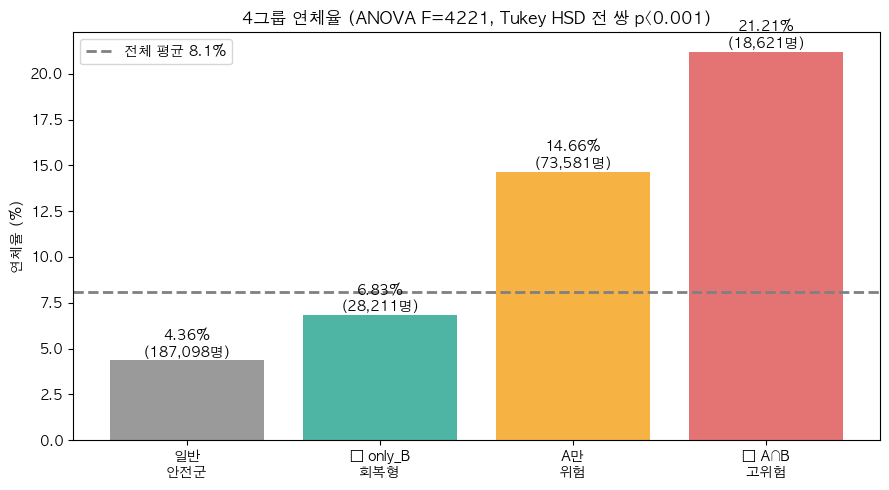

In [6]:
df['group4']='neither'
df.loc[df['only_B']==1,'group4']='only_B'
df.loc[df['risk_AB']==1,'group4']='risk_AB'
df.loc[df['risk_A_only']==1,'group4']='risk_A_only'

# One-way ANOVA
from scipy.stats import f_oneway
groups=[df[df['group4']==g]['TARGET'].values for g in ['neither','only_B','risk_A_only','risk_AB']]
f_stat,p_val=f_oneway(*groups)
print(f'One-way ANOVA: F={f_stat:.2f}, p={p_val:.2e}')

# Tukey HSD
tukey=pairwise_tukeyhsd(df['TARGET'],df['group4'],alpha=0.05)
print('\n=== Tukey HSD 결과 ===')
print(tukey)

# Cohen's h
p_ob=df[df['only_B']==1]['TARGET'].mean()
p_ab=df[df['risk_AB']==1]['TARGET'].mean()
h_val=cohens_h(p_ob,p_ab)
print(f'\nCohen\'s h (only_B vs A∩B): {h_val:.4f}')
print(f'only_B: {p_ob*100:.2f}%  A∩B: {p_ab*100:.2f}%  격차: {p_ab/p_ob:.2f}배')

# 4그룹 시각화
order=['neither','only_B','risk_A_only','risk_AB']
labels=['일반\n안전군','🟢 only_B\n회복형','A만\n위험','🔴 A∩B\n고위험']
colors=['#888888','#2fa896','#f5a623','#e05c5c']
dr_4=[df[df['group4']==g]['TARGET'].mean()*100 for g in order]
n_4=[len(df[df['group4']==g]) for g in order]
fig,ax=plt.subplots(figsize=(9,5))
bars=ax.bar(labels,dr_4,color=colors,alpha=0.85)
for bar,v,n in zip(bars,dr_4,n_4):
    ax.text(bar.get_x()+bar.get_width()/2,v+0.2,f'{v:.2f}%\n({n:,}명)',
            ha='center',fontsize=10,fontweight='bold')
ax.axhline(df['TARGET'].mean()*100,color='gray',lw=2,ls='--',label=f'전체 평균 {df["TARGET"].mean()*100:.1f}%')
ax.set_ylabel('연체율 (%)',fontsize=10)
ax.set_title(f'4그룹 연체율 (ANOVA F={f_stat:.0f}, Tukey HSD 전 쌍 p<0.001)',fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()

## 5. 결과 저장

In [7]:
summary=pd.DataFrame([
    ('성별','카이제곱','Cramer\'s V=0.055','very small','p≈4.39e-202'),
    ('연령','Mann-Whitney','Cohen\'s d=−0.288','small','p<1e-300'),
    ('EXT_SOURCE 평균','t-test','Cohen\'s d=−0.836','large 🔥','p<1e-300'),
    ('DTI 단순','Mann-Whitney','Cohen\'s d=−0.028','negligible','p=0.32'),
    ('직업 (소득통제)','ANCOVA','F=76.33','독립 효과','p<1e-264'),
    ('소득×DTI 교호작용','2-way ANOVA','F=75.56','교호작용','p<1e-300'),
    ('only_B vs A∩B','ANOVA+Tukey','Cohen\'s h=0.428','3.11배 격차','p<0.001'),
],columns=['변수','검정','Effect Size','해석','유의성'])
summary.to_csv(os.path.join(OUT_DIR,'04b_statistical_summary.csv'),index=False,encoding='utf-8-sig')
print('✅ 저장: 04b_statistical_summary.csv')

✅ 저장: 04b_statistical_summary.csv
